# DreamerV4: Learning to Act in an Imagined World

*A hands-on companion to Chapter 10.14 of World Models from Scratch.*

An autonomous agent must learn which actions to take to achieve its goals. This requires understanding how its actions affect the environment and which outcomes lead to better decisions. An agent cannot test every possible action in the physical world because real-world interactions are costly, time-consuming, and sometimes unsafe.

DreamerV4 addresses this challenge by allowing agents to learn from imagined interactions inside a learned world model.

**Key Question:** How does a video prediction model become an environment in which an agent can learn?

The code below is intentially small and illustrative. Some cells only define functions or modules; they are not trained DreamerV4 components. All original code cells are preserved unchanged. [Read the source chapter](https://github.com/nahidalam/world_model_from_scratch/blob/main/chapters/chapter_10/14-dreamer-series-primer.md).

## Before we begin

DreamerV1–V3 use latent imagination and actor–critic learning. DreamerV4 moves toward a generative video world model trained on offline data. The loop is essentially **video -> latent tokens -> action-conditioned predictions -> imagined rewards -> policy improvement**.

Run the cells in order. PyTorch is required; if unavailable, run `%pip install torch`. Synthetic inputs keep the examples lightweight. No pretrained checkpoint or Minecraft installation is needed.

In [1]:
import torch
torch.manual_seed(0)
print('PyTorch ready:', torch.__version__)

PyTorch ready: 2.11.0+cu130


## 1. Architecture



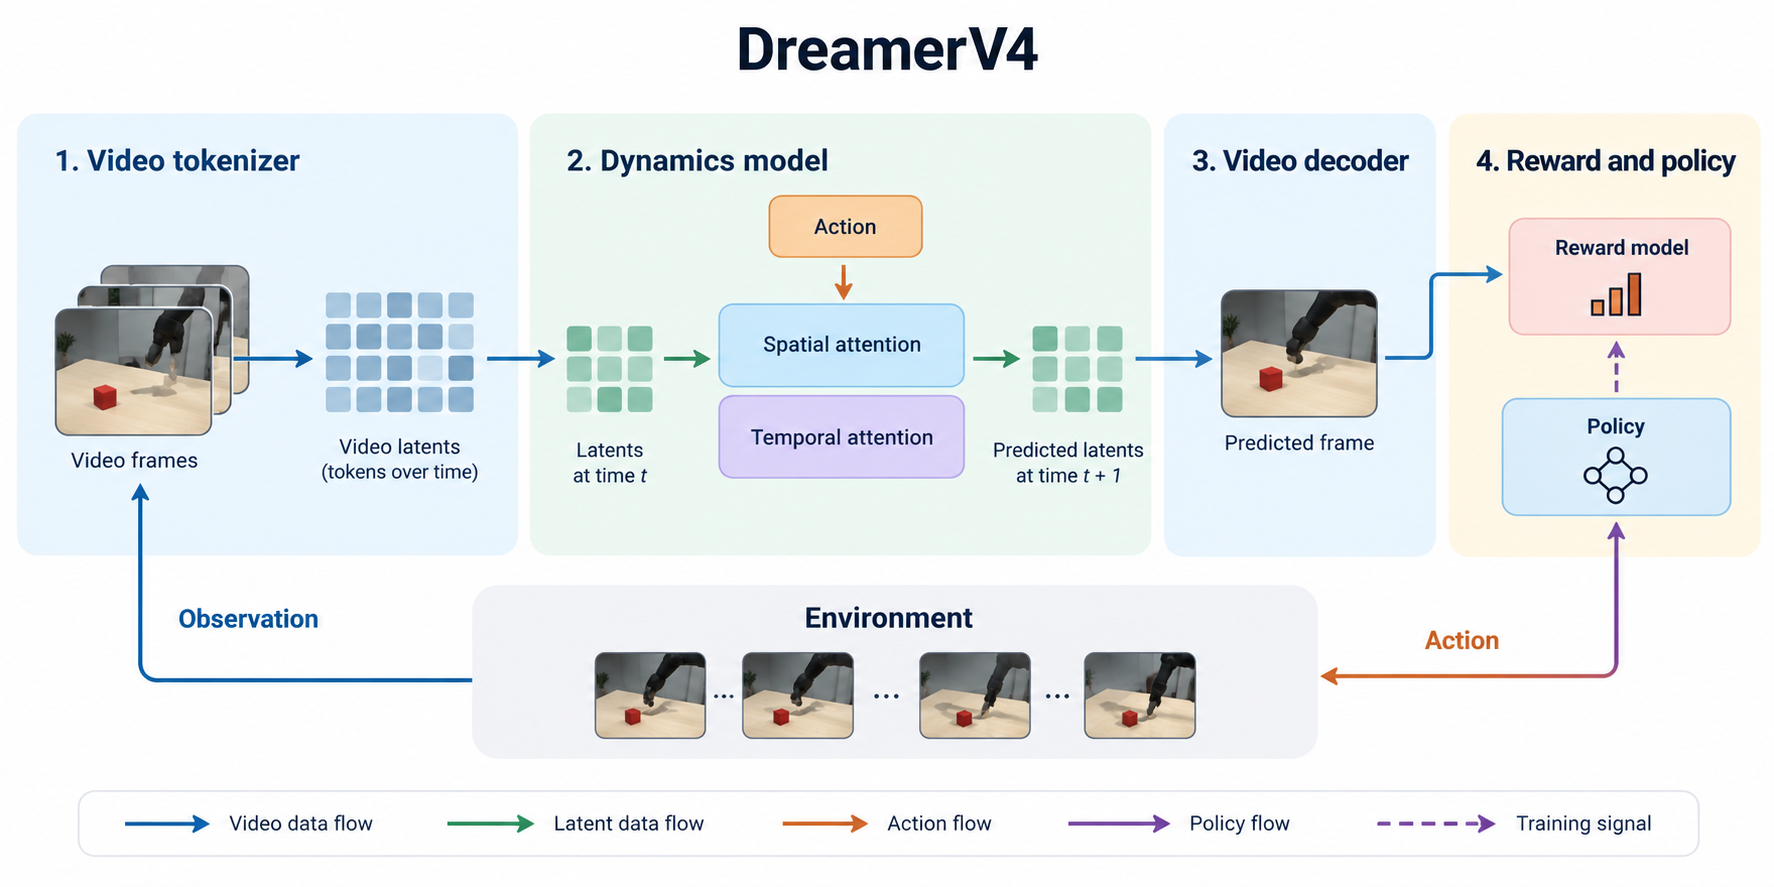

## 1. What is one step for an agent?

Imagine a character standing in front of a wall. The agent sees an image and must decide whether to walk, turn, or stop. A **tokenizer** compresses the observation; a **dynamics model** represents how the world evolves; a **policy** selects an action.

The function below is an interface connecting those roles.

In [2]:
# One frame-level interface for the three phases. Each callable is trained
# separately or finetuned as described below.
def agent_step(tokenizer, dynamics, policy, frames, task, action):
    # compress the observed frames
    context = tokenizer(frames)                 # [batch, time, latent_dim]
    # predict next frame's latent vector
    next_latent = dynamics(context, action)      # one imagined next frame

    # score possible actions
    action_logits = policy(next_latent, task)
    return next_latent, action_logits

### Try it: one agent step

This miniature example uses deterministic stand-ins for the tokenizer, dynamics, and policy. Change the action to see how the predicted latent and selected action change. The example demonstrates the interface; the full learned models are introduced below.

In [ ]:
def toy_tokenizer(frames):
    return frames.mean(dim=(2, 3))  # [batch, time, channels]

def toy_dynamics(context, action):
    return context[:, -1] + 0.2 * action.float().unsqueeze(-1)

def toy_policy(next_latent, task):
    return torch.stack([next_latent[:, 0], -next_latent[:, 0]], dim=-1)

frames = torch.tensor([[[[1., 2.], [3., 4.]], [[2., 3.], [4., 5.]]]])
frames = frames.unsqueeze(-1)  # [batch=1, time=2, height=2, width=2, channels=1]
for selected_action in (torch.tensor([0]), torch.tensor([2])):
    future, logits = agent_step(toy_tokenizer, toy_dynamics, toy_policy,
                                frames, "move", selected_action)
    print(f"Action {selected_action.item()}: latent {future.flatten().tolist()}, policy scores {logits.flatten().tolist()}")

## 2. Causal video tokenizer: what may each token see?

DreamerV4 learns to predict how an environment changes over time. To do this, it first needs a compact representation of video that preserves the information needed to understand the scene and its dynamics.

A video tokenizer converts frames into smaller representations called **latent tokens**. During training, the tokenizer must learn to represent each frame using only information available up to that point in time. This is important because an agent predicting the next state cannot access future observations.

DreamerV4 uses **block-causal attention** to control how information flows between video tokens. Tokens within the same frame can attend to one another and to tokens from earlier frames. They cannot attend to tokens from future frames. This allows the model to capture spatial relationships within a frame while preserving the temporal order of the video.

The following code demonstrates two components of this process:

1. **Block-causal attention mask:** Defines which tokens can exchange information based on their frame positions.
2. **Masked patch reconstruction:** Hides selected patches so the tokenizer can learn to reconstruct missing visual information from the available context.


In [3]:
import torch


# this function controls what each token can see
# Every token can see all tokens in its own frame and earlier frames, but none in future frames
def block_causal_mask(num_frames: int, tokens_per_frame: int) -> torch.Tensor:
    frame_id = torch.arange(num_frames).repeat_interleave(tokens_per_frame)
    return frame_id[None, :] <= frame_id[:, None]

visible = block_causal_mask(num_frames=3, tokens_per_frame=4)
assert visible[:4, 4:].sum() == 0      # frame 0 cannot see future frames
assert visible[4:8, :8].all()          # frame 1 sees frames 0 and 1


# this function changes the input itself.
# For each patch in each batch item, it randomly decides whether to keep its entire channel vector or replace it with mask_token
def masked_patch_input(patches: torch.Tensor, mask_token: torch.Tensor,
                       drop_probability: float) -> torch.Tensor:
    # patches: [batch, num_patches, channels]
    keep = torch.rand(patches.shape[:2], device=patches.device) >= drop_probability
    return torch.where(keep[..., None], patches, mask_token)

### Try it: inspect the attention mask

Each row is a query token, and each column is a token it can read. A value of `1` means visible. The second demonstration shows which patches were replaced by the mask token.

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 3.5))
plt.imshow(visible.int(), cmap="Blues", vmin=0, vmax=1)
plt.xticks([1.5, 5.5, 9.5], ["Frame 0", "Frame 1", "Frame 2"])
plt.yticks([1.5, 5.5, 9.5], ["Frame 0", "Frame 1", "Frame 2"])
plt.xlabel("Key frame"); plt.ylabel("Query frame")
plt.title("Block-causal visibility")
plt.colorbar(label="Visible")
plt.show()

patches = torch.arange(1, 13, dtype=torch.float32).reshape(1, 6, 2)
masked = masked_patch_input(patches, torch.tensor([-1., -1.]), 0.5)
print("Original patches:\n", patches[0])
print("Masked patches (-1 indicates hidden):\n", masked[0])

## 3. Dynamics Model: Predicting the Effects of Actions

The video tokenizer provides a compact representation of the environment. The next step is to learn how this representation changes over time as an agent takes different actions.

For an agent to make decisions, the world model must predict the consequences of its actions. For example, if an agent moves forward, the model should predict how the scene changes as a result of that movement. If the agent turns left instead, the predicted future should reflect that different action. This ability to predict action-dependent outcomes is essential for learning effective behavior through imagined interactions.

DreamerV4 uses an **action-conditioned dynamics model** to predict future video representations. Given the current visual context and the agent's action, the model predicts the latent representation of the resulting future frame. The predicted latents can then be decoded into video frames.

The dynamics model combines three components:

1. **Spatial attention:** Captures relationships between tokens within each video frame, such as the positions and arrangements of objects.
2. **Temporal attention:** Captures how information evolves across frames, allowing the model to learn changes in the environment over time.
3. **Action embedding:** Converts the agent's action into a vector representation that is combined with the video tokens. This allows the model to condition its predictions on the action taken.

The following code implements a simplified version of this architecture.

In [4]:
import torch
from torch import nn

class TinyAxialDynamics(nn.Module):
    def __init__(self, latent_dim: int, action_count: int) -> None:
        super().__init__()
        self.action = nn.Embedding(action_count, latent_dim)
        self.spatial = nn.MultiheadAttention(latent_dim, num_heads=2, batch_first=True)
        self.temporal = nn.MultiheadAttention(latent_dim, num_heads=2, batch_first=True)

    def forward(self, tokens: torch.Tensor, actions: torch.Tensor) -> torch.Tensor:
        # tokens: [batch, time, spatial_tokens, latent_dim]
        batch, time, spatial_tokens, width = tokens.shape
        x = tokens + self.action(actions)[:, :, None, :]
        # Spatial attention: group each frame's patches into one sequence.
        # Shape: [batch * time, spatial_tokens, width].
        x = x.reshape(batch * time, spatial_tokens, width)
        x, _ = self.spatial(x, x, x, need_weights=False)

        # Temporal attention: group each patch position across frames.
        # Shape: [batch * spatial_tokens, time, width].
        x = x.reshape(batch, time, spatial_tokens, width).transpose(1, 2)
        x = x.reshape(batch * spatial_tokens, time, width)
        # Mask future frames so each time step sees only itself and the past.
        future = torch.triu(torch.ones(time, time, dtype=torch.bool,
                                      device=tokens.device), diagonal=1)
        x, _ = self.temporal(x, x, x, attn_mask=future, need_weights=False)
        return x.reshape(batch, spatial_tokens, time, width).transpose(1, 2)

### Try it: change the action

The model below is randomly initialized, so its outputs are demonstrations of tensor flow rather than learned physics. We hold the video tokens fixed and change the action to verify that action conditioning changes the output.

In [ ]:
torch.manual_seed(3)
model = TinyAxialDynamics(latent_dim=8, action_count=4).eval()
tokens = torch.randn(1, 3, 2, 8)
actions_a = torch.zeros(1, 3, dtype=torch.long)
actions_b = actions_a.clone()
actions_b[:, 1] = 2
with torch.no_grad():
    prediction_a = model(tokens, actions_a)
    prediction_b = model(tokens, actions_b)
print("Input shape:", tuple(tokens.shape))
print("Output shape:", tuple(prediction_a.shape))
print("Mean absolute change after modifying action at frame 1:")
print((prediction_a - prediction_b).abs().mean(dim=(0, 2, 3)).tolist())
print("Frame 0 remains unchanged because temporal attention is causal.")

## 4. Shortcut Forcing: Efficient Generation of Future States

In the previous section, we learned how DreamerV4 predicts future video representations based on the agent's actions. To train an agent through imagined experience, the world model must generate many such predictions. The computational cost of generating each future state therefore becomes an important consideration.

DreamerV4 uses a generative approach based on **flow matching**. The model starts with noisy latent representations and progressively transforms them into representations of future video frames. This process typically requires multiple refinement steps to produce an accurate prediction.

During policy training, the agent may need to imagine thousands of trajectories, each containing multiple future states. Running many refinement steps for every predicted state would make this process computationally expensive.

DreamerV4 addresses this challenge using **shortcut forcing**, which trains the model to generate future states with fewer refinement steps while maintaining prediction quality.

The key idea is to learn how to make larger updates in latent space instead of relying on many small updates. For example, rather than taking dozens of refinement steps to generate a future frame, the model can learn to produce a prediction using just four steps.

The following code demonstrates three components of shortcut forcing:

1. **Velocity prediction (`velocity`):** Predicts the direction in latent space that moves a noisy representation toward a generated sample.
2. **Shortcut training (`shortcut_loss`):** Trains the model to make consistent predictions across different step sizes, allowing it to learn larger refinement steps.
3. **Four-step generation (`sample_four_steps`):** Uses the learned velocity predictions to progressively update a noisy latent representation in four steps.

This makes it more practical for DreamerV4 to simulate long trajectories and train agents through imagined experience.

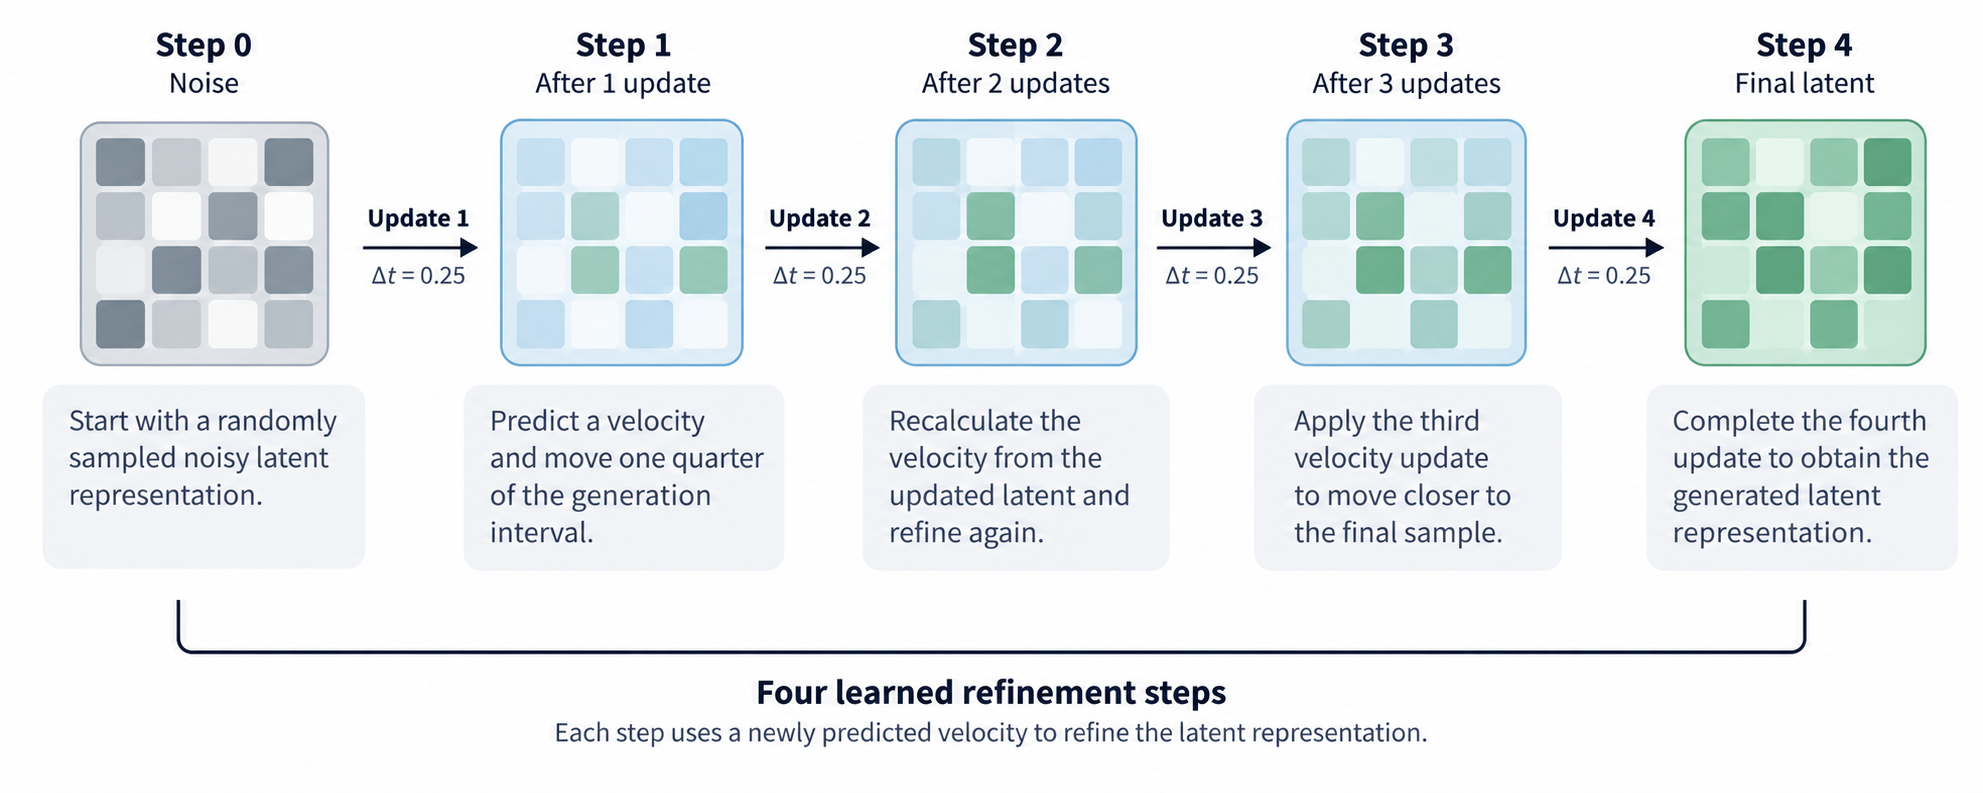

In [5]:
import torch
import torch.nn.functional as F

def velocity(noisy, predicted_clean, tau):
    # Turn a clean-latent prediction into a direction from the current noisy latent.
    return (predicted_clean - noisy) / (1 - tau)

def shortcut_loss(predict_clean, noisy, clean, tau, step, actions, finest):
    # Train the model to predict the clean latent for the requested step size.
    predicted = predict_clean(noisy, tau, step, actions)
    if step == finest:
        # At the smallest step size, compare directly with the known clean latent.
        error = F.mse_loss(predicted, clean, reduction="none")
    else:
        with torch.no_grad():
            # Use two half steps to build a target for one larger shortcut step.
            half = step / 2
            first = velocity(noisy, predict_clean(noisy, tau, half, actions), tau)
            middle = noisy + half * first
            second = velocity(middle, predict_clean(middle, tau + half,
                                                    half, actions), tau + half)
            target_velocity = (first + second) / 2
        # Match the large step's direction to the two-half-step direction.
        error = (velocity(noisy, predicted, tau) - target_velocity).square()
        # Undo the 1 / (1 - tau) scale introduced by velocity().
        error = (1 - tau).square() * error
    # Weight examples by their position along the noise-to-clean path.
    return ((0.9 * tau + 0.1) * error).mean()

def sample_four_steps(predict_clean, shape, actions, device):
    # Start from noise and move toward a clean latent in four equal steps.
    latent = torch.randn(shape, device=device)
    for index in range(4):
        tau = index / 4
        predicted = predict_clean(latent, tau, 0.25, actions)
        # Euler update: current latent + step size * predicted direction.
        latent = latent + 0.25 * velocity(latent, predicted, tau)
    return latent

### Try it: watch four refinement steps

For a visible demonstration, we use a simple clean-latent predictor that always points toward a known target. The four-step sampler still calls the original `sample_four_steps` function. We also compare a coarse-step consistency loss with its two-half-step target.

In [ ]:
target = torch.tensor([[1., -1., 0.5]])
def demonstration_predict_clean(noisy, tau, step, actions):
    return target.expand_as(noisy)

torch.manual_seed(4)
result = sample_four_steps(demonstration_predict_clean, (1, 3), None, "cpu")
print("Target latent:", target.flatten().tolist())
print("Generated latent after four updates:", result.flatten().tolist())
print("Distance to target:", (result - target).norm().item())

noise = torch.randn(1, 3)
tau = torch.tensor(0.25)
fine_loss = shortcut_loss(demonstration_predict_clean, noise, target, tau, 0.125, None, 0.125)
coarse_loss = shortcut_loss(demonstration_predict_clean, noise, target, tau, 0.25, None, 0.125)
print(f"Fine supervision loss: {fine_loss.item():.6f}")
print(f"Shortcut consistency loss: {coarse_loss.item():.6f}")

## 5. Learning from Videos Without Action Labels

Training an action-conditioned world model requires understanding how actions affect the environment. Ideally, the training data contains video frames paired with the actions that produced the observed changes. For example, a robot dataset might contain camera recordings alongside commands such as moving forward, turning, or grasping an object.

However, large collections of videos are available without corresponding action labels. These videos still provide valuable information about **visual dynamics**, including how objects move, how their positions change over time, how objects interact, and how scenes evolve.

For example, a video of a ball rolling across a table can teach the model about the ball's motion, its interaction with the surface, and how its position changes between frames. The model learns these patterns by predicting future video representations from earlier observations.

DreamerV4 uses two types of training data:

1. **Action-labeled videos:** Teach the model how specific actions affect future states. For example, how a robot's movement command changes its position or how a grasping action changes an object's location.
2. **Unlabeled videos:** Teach the model general patterns of visual dynamics by learning to predict how scenes evolve over time, even when the actions responsible for those changes are unknown.

To support both types of data, DreamerV4 introduces a learned **unknown-action embedding**. This is a trainable vector used when action labels are unavailable. It allows the dynamics model to learn from video sequences using the same architecture.

By combining action-labeled and unlabeled videos during training, DreamerV4 learns general visual dynamics from a wider range of video data while also learning how specific actions influence the environment.

The following code demonstrates how the model uses known action embeddings when labels are available and a learned unknown-action embedding when they are missing.

In [6]:
import torch
from torch import nn

action_embedding = nn.Embedding(12, 32)
# One trainable vector stands in for every action label missing from a video.
unknown_action = nn.Parameter(torch.zeros(32))

def action_token(action_id: torch.Tensor, has_label: torch.Tensor) -> torch.Tensor:
    recorded = action_embedding(action_id)
    # Keep the recorded embedding where a label exists; otherwise use the placeholder.
    return torch.where(has_label[..., None], recorded, unknown_action)

ids = torch.tensor([[2, 5], [0, 0]])
labeled = torch.tensor([[True, True], [False, False]])
assert torch.equal(action_token(ids, labeled)[1, 0], unknown_action)

### Try it: compare labeled and unlabeled inputs

The placeholder is a trainable vector shared by positions without an action label. We display a small slice of the embeddings to make the selection visible.

In [ ]:
selected = action_token(ids, labeled)
print("Labels available:\n", labeled)
print("Action IDs:\n", ids)
print("Embedding shape:", tuple(selected.shape))
print("Known action embedding (first four values):", selected[0, 0, :4].detach().tolist())
print("Unknown action embedding (first four values):", selected[1, 0, :4].detach().tolist())
print("Unknown-action vector receives gradients:", unknown_action.requires_grad)

## 6. Agent Finetuning: Learning Actions and Rewards

In the previous sections, we learned how DreamerV4 builds a world model that predicts future video representations based on observations and actions. The next step is to use these learned representations to support decision-making.

To train an agent, DreamerV4 introduces two components:

1. **Policy head:** Predicts a probability distribution over possible actions given the current visual context. During finetuning, it learns to reproduce the actions recorded in the training trajectories. This is a form of **behavior cloning**, where the recorded actions serve as the training targets.
2. **Reward head:** Predicts the reward associated with an observed state or outcome. It learns from recorded reward values that indicate progress toward the task.

DreamerV4 also introduces **agent tokens** that allow the model to process information for action and reward prediction. An attention mask controls how information flows between video tokens and agent tokens, allowing the agent to make predictions using the available visual context.

During finetuning, the policy head is trained using a supervised action-prediction loss. For each observation, the model predicts a distribution over actions and compares it with the action recorded in the training trajectory. The reward head is trained separately to predict the corresponding reward.

The following code demonstrates three components of agent finetuning:

1. **Attention masking:** Defines how video tokens and agent tokens exchange information.
2. **Policy and reward heads:** Convert learned representations into action probabilities and reward predictions.
3. **Training losses:** Compare predicted actions with recorded actions and predicted rewards with their target values.

This stage produces an initial policy that learns from recorded behavior and a reward model that evaluates predicted outcomes. In the next section, DreamerV4 improves the policy through imagined trajectories generated by the world model.

In [7]:
import torch
import torch.nn.functional as F
from torch import nn

def agent_attention_mask(video_tokens: int, agent_tokens: int) -> torch.Tensor:
    count = video_tokens + agent_tokens
    blocked = torch.zeros(count, count, dtype=torch.bool)
    # True blocks video-token queries from reading agent-token keys.
    # Agent-token queries may still read video tokens.
    blocked[:video_tokens, video_tokens:] = True  # query rows, key columns
    return blocked

# Stand-in hidden states for four training examples.
hidden = torch.randn(4, 16)
policy_head = nn.Linear(16, 8)
reward_head = nn.Linear(16, 1)
recorded_actions = torch.tensor([1, 2, 3, 4])
recorded_rewards = torch.tensor([0.0, 1.0, 0.0, 2.0])
# Copy recorded actions and predict recorded rewards from the same hidden states.
clone_loss = F.cross_entropy(policy_head(hidden), recorded_actions)
reward_loss = F.mse_loss(reward_head(hidden).squeeze(-1), recorded_rewards)
loss = clone_loss + reward_loss

### Try it: inspect the mask and perform one supervised update

The policy head learns from recorded action IDs, while the reward head learns from recorded reward values. The small training step below shows the combined loss before and after one optimizer update.

In [ ]:
mask = agent_attention_mask(video_tokens=3, agent_tokens=2)
print("Attention mask (1 = blocked):\n", mask.int())
optimizer = torch.optim.SGD(list(policy_head.parameters()) + list(reward_head.parameters()), lr=0.05)
before = loss.item()
optimizer.zero_grad()
loss.backward()
optimizer.step()
after = (F.cross_entropy(policy_head(hidden), recorded_actions)
         + F.mse_loss(reward_head(hidden).squeeze(-1), recorded_rewards)).item()
print(f"Combined supervised loss: {before:.4f} before, {after:.4f} after one update")

## 7. Imagination Training: Improving the Policy Through Simulated Experience

In the previous section, DreamerV4 learned an initial policy by predicting actions from recorded trajectories. The next step is to improve this policy by learning which actions lead to better outcomes.

DreamerV4 uses **imagination training**, where the agent interacts with its learned world model to generate simulated experiences. The world model predicts how the environment responds to actions, allowing the agent to explore different behaviors and learn from their predicted consequences.

### Training Inputs

Imagination training begins with a visual context from recorded experience. The video tokenizer converts this context into latent representations that serve as the starting point for an imagined trajectory.

The training process uses five components:

1. **World model:** Predicts future latent video representations conditioned on the current context and selected actions.
2. **Policy:** Selects actions based on the current imagined state.
3. **Reward model:** Predicts the reward associated with each imagined outcome.
4. **Value model:** Estimates the expected future rewards from each imagined state.
5. **Behavior prior:** Provides a reference action distribution learned from recorded trajectories.


### Understanding Imagined Rollouts

A **rollout** is a sequence of states, actions, and rewards generated as an agent interacts with an environment over multiple time steps. In traditional reinforcement learning, the agent generates rollouts by taking actions in the actual environment and observing their consequences.

DreamerV4 generates **imagined rollouts** inside its learned world model. Starting from a visual context taken from recorded experience, the agent repeatedly selects actions and uses the world model to predict what happens next.

For example, consider an agent learning to navigate toward a target:

1. **Initial state:** The agent observes its current position and the target ahead.
2. **First action:** The policy selects a forward movement. The world model predicts the resulting state, and the reward model estimates the reward.
3. **Second action:** Based on the predicted state, the policy selects another action, such as turning toward the target. The world model predicts the next state and its reward.
4. **Subsequent actions:** The process continues for a fixed number of steps, producing a sequence of imagined states, actions, and rewards.

The number of predicted transitions is called the **rollout horizon**. For example, a horizon of 15 means the agent imagines 15 consecutive actions and their predicted consequences.

At each step, the value model also estimates the expected future rewards from the current imagined state. These estimates help the agent evaluate actions based on their longer-term consequences.

Once the rollout is complete, DreamerV4 uses the predicted rewards and value estimates to calculate training targets. The policy then learns to favor actions associated with higher expected returns.

By generating many rollouts from different starting contexts, the agent can explore alternative behaviors and improve its policy through simulated experience.

### Generating Imagined Experience

Starting from the initial context, the policy samples an action. The world model predicts the resulting future state, and the reward model estimates its reward. The value model estimates the expected future rewards from that state.

This process repeats over multiple steps to generate an **imagined trajectory** containing predicted states, sampled actions, rewards, and value estimates.

These trajectories provide the training data used to improve the policy and value model.

### Learning from Imagined Trajectories

DreamerV4 uses the generated experience to update the agent in three stages:

1. **Compute lambda returns:** Combine predicted rewards and value estimates to calculate a return target for each step. Since imagined rollouts have a finite horizon, the final value estimate is used to estimate rewards beyond the rollout. This is called **bootstrapping**.

2. **Update the value model:** Train the value model to predict the calculated returns. This improves its ability to estimate long-term rewards from imagined states.

3. **Update the policy:** Use **Proximal Multi-Policy Optimization (PMPO)** to improve action selection. The policy is encouraged to select actions with positive advantages and reduce the probability of actions with negative advantages. A regularization term keeps the policy close to the behavior prior learned from recorded trajectories, helping it remain within behaviors that the world model can predict more reliably.

During imagination training, the world model, reward model, and behavior prior remain frozen. Only the policy and value model are updated.

### Training Outputs

The result of imagination training is an **improved policy** that selects actions based on their predicted long-term rewards and an **updated value model** that estimates future returns more accurately.

The following code demonstrates the main operations:

1. **`imagine`:** Generates imagined trajectories containing states, actions, predicted rewards, and value estimates.
2. **`lambda_returns`:** Computes return targets from predicted rewards and value estimates.
3. **`pmpo_loss`:** Computes the policy training loss using action advantages and the behavior prior.
4. **`configure_imagination_training`:** Freezes the world model, reward model, and behavior prior while enabling training of the policy and value model.

Together, these components allow DreamerV4 to improve its decision-making through imagined experience generated by its learned world model.

In [8]:
import torch
import torch.nn.functional as F

def imagine(context, policy, sample_next, reward_model, value_model, steps):
    states, actions, rewards, values = [], [], [], []
    for _ in range(steps):
        # Save the current state and its value before choosing an action.
        states.append(context)
        values.append(value_model(context))
        action = policy(context).sample()
        actions.append(action)
        # Move through the learned world model, then score the resulting state.
        context = sample_next(context, action)  # four shortcut steps
        rewards.append(reward_model(context))
    # The final state's value estimates rewards beyond this imagined rollout.
    values.append(value_model(context))          # bootstrap after the horizon
    return states, actions, rewards, values

def lambda_returns(rewards, values, continues, gamma=0.997, lam=0.95):
    # Work backward from the final value estimate to get a target per time step.
    target = values[-1]
    returns = []
    for t in reversed(range(len(rewards))):
        # continues[t] is zero if the imagined episode ends after this step.
        target = rewards[t] + gamma * continues[t] * (
            (1 - lam) * values[t + 1] + lam * target
        )
        returns.append(target)
    # Reverse the collected targets back into chronological order.
    return torch.stack(returns[::-1])

def pmpo_loss(policy_logits, prior_logits, sampled_actions, advantages,
              alpha=0.5, beta=0.3):
    log_prob = torch.distributions.Categorical(logits=policy_logits).log_prob(sampled_actions)
    # Favor sampled actions with nonnegative advantage; suppress the others.
    positive = advantages.detach() >= 0
    negative = ~positive
    pos_loss = -alpha * log_prob[positive].mean() if positive.any() else log_prob.sum() * 0
    neg_loss = (1 - alpha) * log_prob[negative].mean() if negative.any() else log_prob.sum() * 0
    # Keep the learned policy near the frozen offline behavior prior.
    log_policy = F.log_softmax(policy_logits, dim=-1)
    log_prior = F.log_softmax(prior_logits.detach(), dim=-1)
    reverse_kl = (log_policy.exp() * (log_policy - log_prior)).sum(-1).mean()
    return pos_loss + neg_loss + beta * reverse_kl

### Try it: generate an imagined rollout and calculate returns

This one-dimensional toy environment has two actions: move left or move right. The dynamics and reward functions below are illustrative stand-ins. The original `imagine`, `lambda_returns`, and `pmpo_loss` functions perform the rollout and learning calculations.

In [ ]:
from torch.distributions import Categorical

torch.manual_seed(5)
policy_logits = torch.tensor([[0.0, 1.0]], requires_grad=True)
prior_logits = torch.zeros(1, 2)

def toy_policy(state):
    return Categorical(logits=policy_logits.expand(state.shape[0], -1))

def toy_next(state, action):
    return state + torch.where(action == 1, 1., -1.).unsqueeze(-1)

def toy_reward(state):
    return -(3. - state.squeeze(-1)).abs()  # prefer reaching position 3

def toy_value(state):
    return -0.5 * (3. - state.squeeze(-1)).abs()

states, actions, rewards, values = imagine(torch.zeros(1, 1), toy_policy,
                                            toy_next, toy_reward, toy_value, steps=5)
continues = [torch.ones_like(r) for r in rewards]
returns = lambda_returns(rewards, values, continues)
print("Positions:", [round(s.item(), 1) for s in states])
print("Actions (0=left, 1=right):", [a.item() for a in actions])
print("Predicted rewards:", [round(r.item(), 2) for r in rewards])
print("Lambda returns:", [round(v.item(), 2) for v in returns])

sampled = torch.cat(actions)
advantage = (returns.detach().flatten() - torch.stack(values[:-1]).detach().flatten())
loss_pmpo = pmpo_loss(policy_logits.expand(len(actions), -1),
                      prior_logits.expand(len(actions), -1),
                      sampled, advantage)
loss_pmpo.backward()
print(f"PMPO loss: {loss_pmpo.item():.4f}")
print("Gradient on policy logits:", policy_logits.grad.tolist())

### Configuring Trainable Components

During imagination training, DreamerV4 keeps the tokenizer, dynamics model, reward model, and behavior prior frozen. Only the policy and value models are updated using imagined experience.

The following code demonstrates how to configure these components in PyTorch using `requires_grad_()` to control which parameters are trainable and `train()` or `eval()` to set their operating modes.

In [9]:
def configure_imagination_training(tokenizer, dynamics, reward_head,
                                   behavior_prior, policy_head, value_head):
    # Keep the world model, reward model, and behavior prior fixed.
    for module in (tokenizer, dynamics, reward_head, behavior_prior):
        module.eval()
        module.requires_grad_(False)
    # Update only the policy and value heads from the imagined rollouts.
    for module in (policy_head, value_head):
        module.train()
        module.requires_grad_(True)

### Try it: verify which modules can learn

The helper sets the training roles. The printed flags make it easy to verify which networks are trainable during imagination training.

In [ ]:
modules = [nn.Linear(2, 2) for _ in range(6)]
configure_imagination_training(*modules)
for name, module in zip(
    ["Tokenizer", "Dynamics", "Reward", "Behavior prior", "Policy", "Value"], modules
):
    print(f"{name:15s} | train mode: {module.training} | trainable: {next(module.parameters()).requires_grad}")

## 8. Minecraft Diamonds: Evaluating Agent Performance

DreamerV4 demonstrates its ability to learn complex behaviors through the task of collecting diamonds in Minecraft. This is a challenging, long-horizon task that requires an agent to complete multiple interdependent steps, including exploring the environment, gathering resources, crafting tools, and mining diamonds.

Success depends on making a sequence of decisions that contribute toward a distant goal. The agent must learn how its actions affect future opportunities and select behaviors that eventually lead to collecting diamonds.

DreamerV4 trains its policy using imagined trajectories generated by the learned world model. The resulting policy is then evaluated in the Minecraft environment to measure how effectively it completes the task.

One way to measure performance is through **episode success rate**, which represents the proportion of evaluation episodes in which the agent successfully achieves the goal.

**Success rate = (Successful episodes / Total episodes) × 100%**

For example, if an agent collects diamonds in 20 out of 100 evaluation episodes, its success rate is 20%.

The following code demonstrates how to calculate the success rate using a small set of illustrative episode outcomes. Each Boolean value indicates whether the agent successfully collected a diamond during an episode.

In [10]:
import torch

obtained_diamond = torch.tensor([False, False, True, False, True])
# Converting success flags to floats makes their mean the fraction of successes.
success_rate = obtained_diamond.float().mean().item()
print(f"Diamond success: {success_rate:.1%} over {len(obtained_diamond)} episodes")

Diamond success: 40.0% over 5 episodes


### Understanding the Results

The example produces a **40% success rate**, with two successful episodes out of five. These are illustrative outcomes used to demonstrate how episode success rate is calculated.

In DreamerV4, the trained policy is evaluated by running episodes in the actual Minecraft environment and measuring how often the agent successfully collects diamonds.

This evaluation measures how effectively the behaviors learned through imagined experience transfer to the actual environment. A higher success rate indicates that the agent is more consistently achieving its goal.

## 9. Limitations of DreamerV4

DreamerV4 demonstrates how a generative world model can support agent training through imagined experience. The effectiveness of this approach depends on the accuracy of the learned dynamics, the quality of the training data, and the computational resources available.

Several limitations affect how reliably DreamerV4 can generate imagined experience and improve an agent's policy.

1. **Long-horizon prediction:** During imagination training, each predicted state becomes the starting point for the next prediction. Small errors can accumulate across a rollout, causing later states and rewards to become less accurate. As a result, the policy may learn from trajectories that differ from what would happen in the actual environment.

2. **Action consistency:** The world model must accurately predict how the environment responds to different actions. For example, if a robot pushes an object to the left, the predicted movement should reflect that action. When action consequences are inaccurate, the policy may learn to select actions based on incorrect predictions of their outcomes.

3. **Unfamiliar actions:** The world model learns from actions represented in its training data. During imagination training, the policy may explore actions that appear infrequently in those recordings. Predictions for these actions can be less reliable, causing the policy to favor behaviors that work well in the learned model but perform differently in the actual environment.

4. **Computational efficiency:** Training a policy requires generating many imagined trajectories, each containing multiple world-model predictions. The computational cost of these predictions determines how many trajectories can be generated within a training budget. Faster generation allows the agent to learn from more simulated experience and potentially explore a wider range of behaviors.

5. **Generalization:** A world model trained in one environment must learn dynamics that remain useful across different objects, interactions, and physical conditions. When the learned dynamics do not generalize to a new environment, the policy may make decisions based on inaccurate predictions. This makes generalization important for transferring world-model-based training to applications such as robotics.

### Measuring Prediction Error Across Rollouts

One way to evaluate a world model is to compare its predicted latent representations with those obtained from actual observations.

Since imagined rollouts contain multiple consecutive predictions, it is useful to measure how prediction error changes over time. This helps identify whether the model maintains accurate predictions throughout the rollout or whether errors increase as the prediction horizon grows.

The following code implements a **rollout prediction error** metric using mean squared error (MSE). It compares predicted and observed latent representations at each time step, averaging across the batch and latent features while preserving the time dimension.

The resulting error values can be used to analyze how prediction accuracy changes across the rollout horizon and identify where the world model may benefit from further improvement.

In [11]:
import torch

def rollout_error(predicted_latents: torch.Tensor,
                  observed_latents: torch.Tensor) -> torch.Tensor:
    if predicted_latents.shape != observed_latents.shape:
        raise ValueError("Predicted and observed sequences must have the same shape")
    if predicted_latents.ndim < 3:
        raise ValueError("Expected [batch, time, ...] latent sequences")
    # Flatten latent features, then average squared error over batch and features.
    # Keep the time axis so the result shows error at each rollout step.
    return (predicted_latents - observed_latents).square().flatten(2).mean((0, 2))

predicted = torch.randn(2, 4, 8)
observed = torch.randn(2, 4, 8)
error_by_horizon = rollout_error(predicted, observed)
assert error_by_horizon.shape == (4,)

### Try it: visualize error over the rollout horizon

The example creates a sequence with increasing perturbations to illustrate how the metric exposes errors at each step. For an actual evaluation, predicted latents and observed latents would come from aligned trajectories.

In [ ]:
import matplotlib.pyplot as plt
torch.manual_seed(6)
observed = torch.randn(8, 12, 16)
perturbation = torch.randn_like(observed) * torch.linspace(0.05, 0.8, 12)[None, :, None]
predicted = observed + perturbation
errors = rollout_error(predicted, observed)
plt.figure(figsize=(6, 3))
plt.plot(range(1, len(errors) + 1), errors.detach().numpy(), marker="o")
plt.xlabel("Rollout step")
plt.ylabel("Latent mean squared error")
plt.title("Prediction error by horizon (illustrative)")
plt.grid(alpha=0.2)
plt.show()
print("Error at first and last step:", round(errors[0].item(), 4), round(errors[-1].item(), 4))

## Putting It All Together

DreamerV4 demonstrates how a generative world model can be used to train autonomous agents through imagined experience. It combines video representation learning, action-conditioned dynamics, and reinforcement learning into a framework for learning effective behavior from offline data.

The training process brings together several key components:

1. **Video representation:** A causal video tokenizer converts observations into compact latent representations while preserving temporal information.

2. **World prediction:** An action-conditioned dynamics model learns how the environment evolves in response to the agent's actions.

3. **Efficient generation:** Shortcut forcing enables the world model to generate future states using fewer refinement steps, making imagined rollouts computationally practical.

4. **Learning from offline video:** Action-labeled and unlabeled videos provide complementary information about visual dynamics and the effects of actions.

5. **Agent finetuning:** Policy and reward heads learn to predict recorded actions and task rewards from the learned representations.

6. **Imagination training:** The agent generates trajectories inside the world model and improves its policy using predicted rewards, value estimates, and reinforcement learning.

7. **Evaluation:** The trained policy is evaluated in the actual environment to measure how effectively behaviors learned through imagination achieve the task objectives.

### Key Takeaway

DreamerV4 extends the role of a generative world model from predicting future observations to supporting autonomous decision-making. By learning environment dynamics from offline video and training policies through imagined interactions, it provides a framework for improving agent behavior using simulated experience.

The effectiveness of this approach ultimately depends on the accuracy of the world model's predictions, particularly how faithfully it represents the consequences of actions over long trajectories.

### Primary Sources

- [DreamerV1: Dream to Control](https://arxiv.org/abs/1912.01603)
- [DreamerV2: Mastering Atari with Discrete World Models](https://arxiv.org/abs/2010.02193)
- [DreamerV3: Mastering Diverse Domains through World Models](https://arxiv.org/abs/2301.04104)
- [DreamerV4: Training Agents Inside of Scalable World Models](https://arxiv.org/abs/2509.24527)